In [1]:
from pathlib import Path
from hyperpyyaml import load_hyperpyyaml
from speechbrain.utils.parameter_transfer import Pretrainer
import speechbrain as sb
import os
import torch
import torch.nn.functional as F

In [2]:
# 1. Define paths
MODEL_DIR = "/storage/anakuzne/exp/debug3/"
model_dir = Path(MODEL_DIR)
hparams_path = model_dir / "hyperparams.yaml"

# 2. Extract your modules from the hyperparams file
with open(hparams_path, encoding="utf-8") as fin:
    hparams = load_hyperpyyaml(fin)

/home/anastasia/envs/sb/lib/python3.10/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


In [3]:
from speechbrain.tokenizers.SentencePiece import SentencePiece
tokenizer = SentencePiece(
        model_dir=hparams["save_folder"],
        vocab_size=hparams["output_neurons"],
        annotation_train=hparams["train_csv"],
        annotation_read="wrd",
        model_type=hparams["token_type"],
        character_coverage=hparams["character_coverage"],
        bos_id=hparams["bos_index"],
        eos_id=hparams["eos_index"],
    )

In [4]:
from speechbrain.utils.checkpoints import Checkpointer

checkpointer = Checkpointer(
    checkpoints_dir=f"{hparams['output_folder']}/save",
    recoverables={
        # Pass the entire modules dictionary so SpeechBrain matches "enc", "seq_lin", etc.
        "model": hparams["model"], 
        # Schedulers and counters live directly at the root of hparams
        "scheduler": hparams["scheduler"],
        "counter": hparams["epoch_counter"],
    },
)
ckpts = checkpointer.find_checkpoints(
            max_key=None,
            min_key=None,
            max_num_checkpoints=hparams["avg_checkpoints"],
        )

ckpt = sb.utils.checkpoints.average_checkpoints(ckpts, recoverable_name="model")

hparams["model"].load_state_dict(ckpt, strict=True)
hparams["model"].eval()
model = hparams["model"]
model.eval()

ModuleList(
  (0): DAC(
    (encoder): Encoder(
      (block): Sequential(
        (0): ParametrizedConv1d(
          1, 64, kernel_size=(7,), stride=(1,), padding=(3,)
          (parametrizations): ModuleDict(
            (weight): ParametrizationList(
              (0): _WeightNorm()
            )
          )
        )
        (1): EncoderBlock(
          (block): Sequential(
            (0): ResidualUnit(
              (block): Sequential(
                (0): Snake1d()
                (1): ParametrizedConv1d(
                  64, 64, kernel_size=(7,), stride=(1,), padding=(3,)
                  (parametrizations): ModuleDict(
                    (weight): ParametrizationList(
                      (0): _WeightNorm()
                    )
                  )
                )
                (2): Snake1d()
                (3): ParametrizedConv1d(
                  64, 64, kernel_size=(1,), stride=(1,)
                  (parametrizations): ModuleDict(
                    (weight): P

In [5]:
from pathlib import Path
from speechbrain.utils.checkpoints import (
    Checkpointer,
    torch_parameter_transfer,
)


def model_partial_load_hook(obj, path, end_of_epoch):
    # Ignore missing/unexpected model keys during checkpoint recovery.
    del end_of_epoch
    torch_parameter_transfer(obj, path)


# 1. Define your checkpointer
save_dir = Path(hparams["output_folder"]) / "save"

checkpointer = Checkpointer(
    checkpoints_dir=save_dir,
    recoverables={
        "model": hparams["model"],
        "scheduler": hparams["scheduler"],
        "counter": hparams["epoch_counter"],
    },
    custom_load_hooks={
        "model": model_partial_load_hook,
    },
)

# 2. Automatically find and load the latest checkpoint
# This finds the latest checkpoint and injects parameters back into recoverables.
chosen_ckpt = checkpointer.recover_if_possible()

if chosen_ckpt is not None:
    print(f"Successfully loaded the latest checkpoint from: {chosen_ckpt.path}")
else:
    print("Warning: No checkpoint found. Model is using random initialization.")

# 3. Set to evaluation mode
model = hparams["model"]
model.eval()

Successfully loaded the latest checkpoint from: /storage/anakuzne/exp/debug3/save/CKPT+2026-10-14+23-54-20+00


ModuleList(
  (0): DAC(
    (encoder): Encoder(
      (block): Sequential(
        (0): ParametrizedConv1d(
          1, 64, kernel_size=(7,), stride=(1,), padding=(3,)
          (parametrizations): ModuleDict(
            (weight): ParametrizationList(
              (0): _WeightNorm()
            )
          )
        )
        (1): EncoderBlock(
          (block): Sequential(
            (0): ResidualUnit(
              (block): Sequential(
                (0): Snake1d()
                (1): ParametrizedConv1d(
                  64, 64, kernel_size=(7,), stride=(1,), padding=(3,)
                  (parametrizations): ModuleDict(
                    (weight): ParametrizationList(
                      (0): _WeightNorm()
                    )
                  )
                )
                (2): Snake1d()
                (3): ParametrizedConv1d(
                  64, 64, kernel_size=(1,), stride=(1,)
                  (parametrizations): ModuleDict(
                    (weight): P

In [6]:
def dataio_prepare_infer(hparams, tokenizer, test_csv_path):
    test_data = sb.dataio.dataset.DynamicItemDataset.from_csv(
        csv_path=test_csv_path, replacements={"data_root": hparams["data_folder"]}
    )

    # Speaker label pipeline
    @sb.utils.data_pipeline.takes("spk_id")
    @sb.utils.data_pipeline.provides("spk_id")
    def label_pipeline(spk_id):
        spk_id_prefix = spk_id.split("-")[0]
        yield spk_id_prefix
    sb.dataio.dataset.add_dynamic_item([test_data], label_pipeline)

    @sb.utils.data_pipeline.takes("wav")
    @sb.utils.data_pipeline.provides("sig")
    def audio_pipeline(wav):
        sig = sb.dataio.dataio.read_audio(wav)
        return sig
    sb.dataio.dataset.add_dynamic_item([test_data], audio_pipeline)

    @sb.utils.data_pipeline.takes("wrd")
    @sb.utils.data_pipeline.provides("wrd", "char_list", "tokens_list", "tokens")
    def text_pipeline(wrd):
        yield wrd
        char_list = list(wrd)
        yield char_list
        tokens_list = tokenizer.sp.encode_as_ids(wrd)
        yield tokens_list
        tokens = torch.LongTensor(tokens_list)
        yield tokens
    sb.dataio.dataset.add_dynamic_item([test_data], text_pipeline)

    # Set output keys for speaker verification
    sb.dataio.dataset.set_output_keys([test_data], ["id", "sig", "spk_id"])
    return test_data

In [7]:
from IPython.display import Audio, display

# Define two files separately
source_file = "/storage/shared/datasets/LibriSpeech/train-clean-100/163/121908/163-121908-0000.wav"
target_file = "/storage/shared/datasets/LibriSpeech/train-clean-100/163/121908/163-121908-0000.wav"

# Play a file directly
display(Audio(filename=source_file))


In [8]:
from pathlib import Path
import tempfile
import csv
import os

# Define two files separately
#source_file = "/projects/bfje/akuznetsova/datasets/LibriSpeech/train-clean-360/408/122806/408-122806-0088.wav"
#target_file = "/projects/bfje/akuznetsova/datasets/LibriSpeech/train-clean-360/408/122806/408-122806-0088.wav"


def build_single_csv(test_file, csv_name):
    wav_path = Path(test_file)

    # Build a speaker id in the same style as LibriSpeech: speaker-chapter
    speaker = wav_path.parent.parent.name
    chapter = wav_path.parent.name
    spk_id = f"{speaker}-{chapter}"

    # One-row CSV expected by dataio_prepare_infer (columns used: ID, wav, spk_id, wrd)
    tmp_csv = Path(tempfile.gettempdir()) / csv_name
    with open(tmp_csv, "w", newline="", encoding="utf-8") as f:
        writer = csv.DictWriter(f, fieldnames=["ID", "wav", "spk_id", "wrd"])
        writer.writeheader()
        writer.writerow(
            {
                "ID": wav_path.stem,
                "wav": str(wav_path),
                "spk_id": spk_id,
                "wrd": "",  # transcript not needed for speaker-only inference
            }
        )
    return tmp_csv


# Build a separate one-row CSV for each file
source_csv = build_single_csv(source_file, "source_infer.csv")
target_csv = build_single_csv(target_file, "target_infer.csv")

# Reuse your existing dataio function
source_data = dataio_prepare_infer(hparams, tokenizer, str(source_csv))
target_data = dataio_prepare_infer(hparams, tokenizer, str(target_csv))

# Inspect and fetch first sample from each
print("source:", source_data[0]["id"], source_data[0]["spk_id"], source_data[0]["sig"].shape)
print("target:", target_data[0]["id"], target_data[0]["spk_id"], target_data[0]["sig"].shape)

source: 163-121908-0000 163-121908 torch.Size([235680])
target: 163-121908-0000 163-121908 torch.Size([235680])


## Reconstruction pipeline

In [11]:
import torch
import speechbrain as sb

# 1. Device Management
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Grab the ModuleList and push ALL sub-modules to the active device
model = hparams["model"].to(device)
model.eval() 

# 2. Extract components from your ModuleList layout
codec_model = model[0]
disentangle_module = model[1]

# 3. Process the audio sample
source_wav = source_data[0]["sig"].to(device)
if source_wav.ndim == 1:
    encoder_input = source_wav.unsqueeze(0).unsqueeze(0)
elif source_wav.ndim == 2:
    encoder_input = source_wav.unsqueeze(1)
else:
    encoder_input = source_wav

with torch.no_grad():
    # Step 1: Extract DAC encoder latent
    z = codec_model.encoder(encoder_input)  # [B, D, T]
    
    # Step 2: Forward through disentangler module
    disentangle_outs = disentangle_module(z, stage=sb.Stage.TEST)
    h_stacked = disentangle_outs[-1]  # [B, Num_Layers, dict_dim, T]
    
    recon_layers = []
    num_layers = h_stacked.size(1)

    # Step 3: Reconstruct z
    for i in range(num_layers):
        sparse_module = disentangle_module.sparse_module_list[i]
        h_i = h_stacked[:, i, :, :]  # [B, dict_dim, T]
        print(h_i.shape, sparse_module.W.shape)
        
        # Option A: Full linear reconstruction directly
        # W shape: [input_dim, dict_dim]
        x_approx = torch.einsum("dk, bkt -> bdt", sparse_module.W, h_i)
        
        # Add dictionary bias if present in sparse_module
        if hasattr(sparse_module, "bias") and sparse_module.bias is not None:
            x_approx = x_approx + sparse_module.bias.view(1, -1, 1)
            
        recon_layers.append(x_approx)

    # Sum across sparse coding layers -> [B, D, T]
    z_reconstructed = torch.stack(recon_layers, dim=0).sum(dim=0)

    # Step 4: Validate Reconstruction Quality
    mse_error = torch.mean((z - z_reconstructed) ** 2).item()
    print(f"Latent Reconstruction MSE (z vs z_recon): {mse_error:.8f}")

    # Step 5: Decode waveform
    # Note: Pass through quantizer first if decoder expects quantized embeddings
    if hasattr(codec_model, "quantizer"):
        quantizer_out = codec_model.quantizer(z_reconstructed)
        print(f"Quantized latent shape: {quantizer_out[0].shape}")
        decoded_wave = codec_model.decoder(quantizer_out[0])
    else:
        decoded_wave = codec_model.decoder(z_reconstructed)
        
    print(f"Decoded wave shape: {decoded_wave.shape}")

torch.Size([1, 1024, 736]) torch.Size([1024, 512])


RuntimeError: einsum(): subscript k has size 1024 for operand 1 which does not broadcast with previously seen size 512

In [36]:
display(Audio(decoded_wave.squeeze().cpu(), rate=16000))

In [37]:
import matplotlib.pyplot as plt


def show_bt_tensor(x, title, sample_idx=0, cmap="magma"):
    # x is expected as [B, T, D]
    mat = x[sample_idx].detach().float().cpu()  # [D, T]
    plt.figure(figsize=(10, 3))
    plt.imshow(mat, aspect="auto", origin="lower", cmap=cmap)
    plt.title(f"{title} | shape={tuple(x.shape)}")
    plt.xlabel("Time")
    plt.ylabel("Feature")
    plt.colorbar()
    plt.tight_layout()
    plt.show()

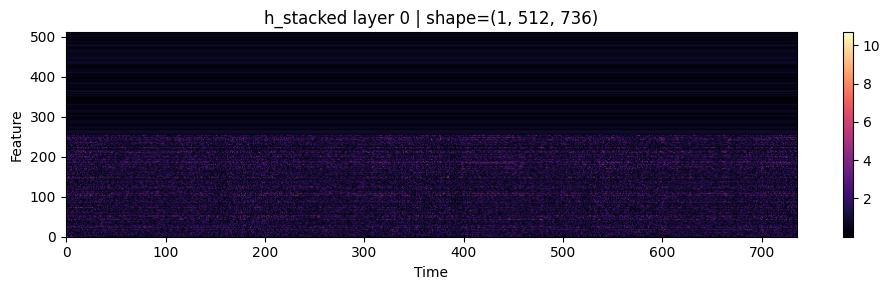

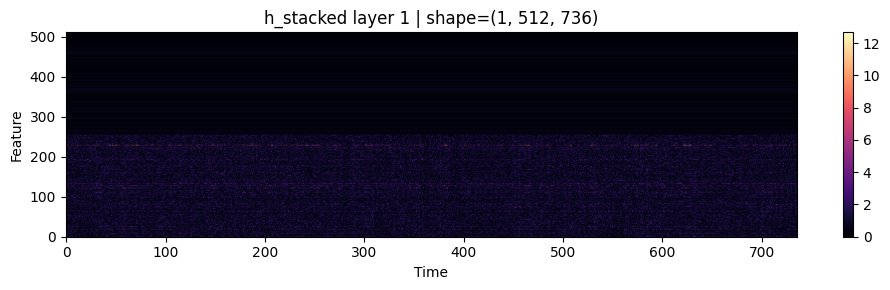

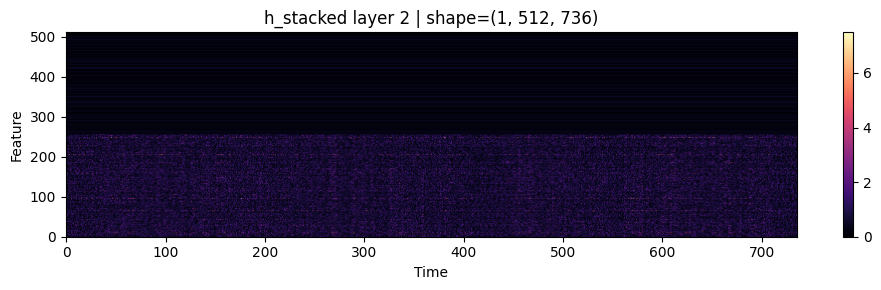

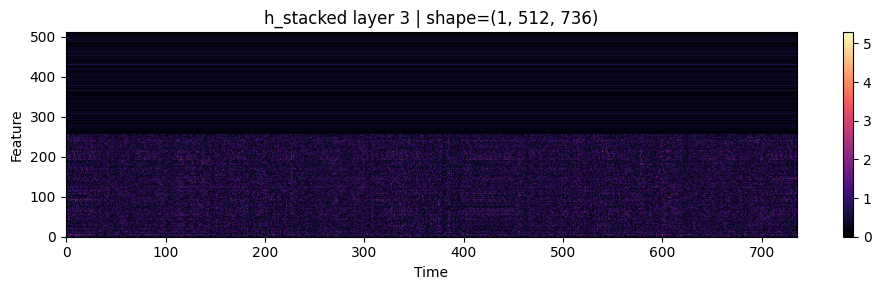

In [39]:
num_layers_to_plot = min(4, h_stacked.shape[1])
for layer_idx in range(num_layers_to_plot):
    show_bt_tensor(h_stacked[:, layer_idx].abs(), f"h_stacked layer {layer_idx}")

In [9]:
import math
import torch
import matplotlib.pyplot as plt

def plot_sparse_layers(h_stacked, n_layers=4, cmap="viridis", figsize=(14, 10), split_dim=32):
    """Plot the first n_layers matrices from h_stacked along dimension 0.

    Expected per-layer matrix shape is [T, F]. This function plots
    x-axis = T (e.g., 201) and y-axis = F (e.g., 64), and draws
    a horizontal separation line at feature dimension split_dim.
    """
    if isinstance(h_stacked, torch.Tensor):
        hs = h_stacked.detach().cpu()
    else:
        hs = torch.as_tensor(h_stacked)

    if hs.ndim < 3:
        raise ValueError(f"Expected h_stacked with shape [L, T, F], got {tuple(hs.shape)}")
    hs = hs.squeeze(0)
    n = min(n_layers, hs.shape[0])
    ncols = 2
    nrows = math.ceil(n / ncols)

    fig, axes = plt.subplots(nrows, ncols, figsize=figsize)
    axes = axes.flatten()
      # Remove batch dimension if present
    print(f"Plotting {n} sparse layers with shape {tuple(hs.shape)}")

    for i in range(n):
        ax = axes[i]
        mat = hs[i].numpy()  # transpose so x=T and y=F
        im = ax.imshow(mat, aspect="auto", origin="lower", cmap=cmap)
        ax.set_title(f"H sparse layer {i + 1}")
        ax.set_xlabel("Time (201)")
        ax.set_ylabel("Feature (64)")

        # Draw boundary between top/bottom parts at feature dimension 32
        if 0 < split_dim < mat.shape[0]:
            ax.axhline(
                y=split_dim - 0.5,
                color="white",
                linestyle="--",
                linewidth=1.8,
                alpha=0.95,
            )

        fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

    # Hide unused subplot slots (if any)
    for j in range(n, len(axes)):
        axes[j].axis("off")

    plt.tight_layout()
    plt.show()

# Plot first 4 sparse layers with separator at dim 32
plot_sparse_layers(h_source, n_layers=4, split_dim=32)

NameError: name 'h_source' is not defined

In [47]:
import matplotlib.pyplot as plt
import torch
import soundfile as sf


def plot_mel_spec(
    waveform,
    sample_rate,
    n_mels=80,
    n_fft=1024,
    hop_length=256,
    win_length=None,
    f_min=0.0,
    f_max=None,
    power=2.0,
    top_db=80.0,
    title="Mel spectrogram",
    cmap="magma",
    figsize=(12, 4),
    ax=None,
):
    """Compute and plot a mel spectrogram from a waveform tensor or array."""
    try:
        import torchaudio
    except ImportError as exc:
        raise ImportError("torchaudio is required to plot mel spectrograms") from exc

    if isinstance(waveform, torch.Tensor):
        audio = waveform.detach().cpu()
    else:
        audio = torch.as_tensor(waveform)

    if audio.ndim == 2:
        if audio.shape[0] == 1:
            audio = audio.squeeze(0)
        elif audio.shape[1] == 1:
            audio = audio.squeeze(1)
        else:
            audio = audio[0]
    elif audio.ndim != 1:
        raise ValueError(f"Expected waveform with shape [T], [1, T], or [C, T], got {tuple(audio.shape)}")

    if win_length is None:
        win_length = n_fft
    if f_max is None:
        f_max = sample_rate / 2

    mel_transform = torchaudio.transforms.MelSpectrogram(
        sample_rate=sample_rate,
        n_fft=n_fft,
        hop_length=hop_length,
        win_length=win_length,
        f_min=f_min,
        f_max=f_max,
        power=power,
        n_mels=n_mels,
        center=True,
        pad_mode="reflect",
        norm="slaney",
        mel_scale="htk",
    )
    amplitude_to_db = torchaudio.transforms.AmplitudeToDB(stype="power", top_db=top_db)

    mel_spec = mel_transform(audio.unsqueeze(0)).squeeze(0)
    mel_spec_db = amplitude_to_db(mel_spec)

    if ax is None:
        fig, ax = plt.subplots(figsize=figsize)
    else:
        fig = ax.figure

    im = ax.imshow(
        mel_spec_db.numpy(),
        origin="lower",
        aspect="auto",
        interpolation="nearest",
        cmap=cmap,
    )
    ax.set_title(title)
    ax.set_xlabel("Frame")
    ax.set_ylabel("Mel bin")
    fig.colorbar(im, ax=ax, format="%+2.0f dB")
    plt.tight_layout()

    return mel_spec_db, fig, ax


In [9]:
import numpy as np


def plot_hspk_hcnt_umap(
    h_list,
    speaker_ids,
    mid,
    layer_idx=0,
    aggregate="frame",
    n_neighbors=15,
    min_dist=0.1,
    random_state=42,
    figsize=(12, 5),
):
    """Plot UMAP projections of H_cnt and H_spk activations, colored by speaker.

    Parameters
    ----------
    h_list : list of dict or torch.Tensor
        Either dicts {"cnt", "spk", "spk_mat"} from `sample_and_run_inference`
        (per-layer [1, L, K, T] features), or `h_stacked` tensors shaped
        [B, L, dict_dim, T]. Every sample contributes one time-frame "cloud".
    speaker_ids : list
        A speaker label per entry in `h_list` (same length as `h_list`).
    mid : int
        Split index along the dict_dim axis: [:mid] is content, [mid:] is speaker.
        Ignored for dict input (already split per layer).
    layer_idx : int
        Which sparse layer (dim 1 of h_stacked) to visualize.
    aggregate : {"frame", "mean", "max"}
        "frame" plots every time-frame as its own point (default, most points).
        "mean"/"max" pool over time first, so each entry in `h_list` contributes
        exactly one point.
    """
    try:
        import umap
    except ImportError as exc:
        raise ImportError(
            "umap-learn is required for this plot. Install it with `pip install umap-learn`."
        ) from exc

    if len(h_list) != len(speaker_ids):
        raise ValueError("h_list and speaker_ids must have the same length")
    if aggregate not in ("frame", "mean", "max"):
        raise ValueError(f"aggregate must be one of 'frame', 'mean', 'max', got {aggregate!r}")

    # Speaker ids may come as "speaker-chapter" or "speaker-chapter-utt"; keep only the speaker part.
    speaker_ids = [str(spk_id).split("-")[0] for spk_id in speaker_ids]

    cnt_frames, spk_frames, frame_labels = [], [], []
    for h_stacked, spk_id in zip(h_list, speaker_ids):
        if isinstance(h_stacked, dict):
            # Output of sample_and_run_inference: cnt/spk_mat are [1, L, K, T].
            h_cnt_all = h_stacked["cnt"].detach().cpu().squeeze(0)  # [L, K_cnt, T]
            h_spk_all = h_stacked.get("spk_mat", h_stacked.get("spk")).detach().cpu().squeeze(0)
            h_cnt = h_cnt_all[layer_idx].T.numpy()  # [T, K_cnt]
            h_spk = h_spk_all[layer_idx].T.numpy()  # [T, K_spk]
        else:
            h = h_stacked.detach().cpu()
            if h.ndim == 4:
                h = h.squeeze(0)  # drop batch dim -> [L, dict_dim, T]
            h_layer = h[layer_idx]  # [dict_dim, T]
            h_cnt = h_layer[:mid, :].T.numpy()  # [T, mid]
            h_spk = h_layer[mid:, :].T.numpy()  # [T, dict_dim - mid]

        if aggregate == "mean":
            h_cnt = h_cnt.mean(axis=0, keepdims=True)
            h_spk = h_spk.mean(axis=0, keepdims=True)
        elif aggregate == "max":
            h_cnt = h_cnt.max(axis=0, keepdims=True)
            h_spk = h_spk.max(axis=0, keepdims=True)

        cnt_frames.append(h_cnt)
        spk_frames.append(h_spk)
        frame_labels.extend([spk_id] * h_cnt.shape[0])

    cnt_frames = np.concatenate(cnt_frames, axis=0)
    spk_frames = np.concatenate(spk_frames, axis=0)
    frame_labels = np.array(frame_labels)
    unique_labels = np.unique(frame_labels)

    reducer_cnt = umap.UMAP(n_neighbors=n_neighbors, min_dist=min_dist, random_state=random_state)
    reducer_spk = umap.UMAP(n_neighbors=n_neighbors, min_dist=min_dist, random_state=random_state)
    cnt_embedding = reducer_cnt.fit_transform(cnt_frames)
    spk_embedding = reducer_spk.fit_transform(spk_frames)

    fig, axes = plt.subplots(1, 2, figsize=figsize)
    n_labels = len(unique_labels)
    if n_labels <= 10:
        colors = plt.get_cmap("tab10")(np.linspace(0, 1, 10))[:n_labels]
    elif n_labels <= 20:
        colors = plt.get_cmap("tab20")(np.linspace(0, 1, 20))[:n_labels]
    else:
        # tab10/tab20 run out of distinct colors; sample a continuous map instead.
        colors = plt.get_cmap("nipy_spectral")(np.linspace(0, 0.95, n_labels))
    for i, label in enumerate(unique_labels):
        mask = frame_labels == label
        axes[0].scatter(cnt_embedding[mask, 0], cnt_embedding[mask, 1], s=6, color=colors[i], label=str(label))
        axes[1].scatter(spk_embedding[mask, 0], spk_embedding[mask, 1], s=6, color=colors[i], label=str(label))

    axes[0].set_title(f"H_cnt UMAP (layer {layer_idx})")
    axes[1].set_title(f"H_spk UMAP (layer {layer_idx})")
    for ax in axes:
        ax.set_xlabel("UMAP-1")
        ax.set_ylabel("UMAP-2")
        ax.legend(title="Speaker", fontsize=8, markerscale=2)
    plt.tight_layout()
    plt.show()

    return cnt_embedding, spk_embedding, frame_labels


In [10]:
import csv
import random
import tempfile
from collections import defaultdict
from pathlib import Path


def sample_and_run_inference(
    hparams,
    tokenizer,
    input_dir,
    n_speakers,
    k_samples,
    codec_model,
    disentangle_module,
    device,
    seed=None,
):
    """Sample N speakers (K files each) from a directory and run codec + disentangle inference.

    Mirrors `dataio_prepare_infer(hparams, tokenizer, test_csv_path)`: a temporary
    CSV is built for the sampled files and fed through the same dataio pipeline,
    so speaker labels ("spk_id") come straight from the dataset rather than being
    re-derived from file paths.

    Returns
    -------
    h_list : list of dict
        One dict per sampled file with per-layer features:
        "cnt" [1, L, K_cnt, T], "spk" [1, L, K_spk, 1], "spk_mat" [1, L, K_spk, T].
    speaker_ids : list of str
        The true speaker id for each sampled file.
    transcripts : list of str
        The LibriSpeech transcript of each sampled file (read from the
        `<speaker>-<chapter>.trans.txt` file next to the audio).
    """
    wav_paths = sorted(
        p for p in Path(input_dir).rglob("*") if p.suffix.lower() in (".wav", ".flac")
    )
    if not wav_paths:
        raise ValueError(f"No .wav/.flac files found under {input_dir}")

    speaker_to_paths = defaultdict(list)
    for wav_path in wav_paths:
        speaker_to_paths[wav_path.parent.parent.name].append(wav_path)

    rng = random.Random(seed)
    all_speakers = sorted(speaker_to_paths)
    n_speakers = min(n_speakers, len(all_speakers))
    chosen_speakers = rng.sample(all_speakers, n_speakers)

    sampled_paths = []
    for speaker in chosen_speakers:
        paths = speaker_to_paths[speaker]
        sampled_paths.extend(rng.sample(paths, min(k_samples, len(paths))))

    def load_transcript(wav_path):
        trans_file = wav_path.parent / f"{wav_path.parent.parent.name}-{wav_path.parent.name}.trans.txt"
        with open(trans_file, encoding="utf-8") as tf:
            for line in tf:
                utt_id, _, text = line.rstrip("\n").partition(" ")
                if utt_id == wav_path.stem:
                    return text
        raise KeyError(f"No transcript for {wav_path.stem} in {trans_file}")

    id_to_transcript = {p.stem: load_transcript(p) for p in sampled_paths}

    tmp_csv = Path(tempfile.gettempdir()) / "sample_infer.csv"
    with open(tmp_csv, "w", newline="", encoding="utf-8") as f:
        writer = csv.DictWriter(f, fieldnames=["ID", "wav", "spk_id", "wrd"])
        writer.writeheader()
        for wav_path in sampled_paths:
            speaker = wav_path.parent.parent.name
            chapter = wav_path.parent.name
            writer.writerow(
                {
                    "ID": wav_path.stem,
                    "wav": str(wav_path),
                    "spk_id": f"{speaker}-{chapter}",
                    "wrd": id_to_transcript[wav_path.stem],
                }
            )

    test_data = dataio_prepare_infer(hparams, tokenizer, str(tmp_csv))

    h_list, speaker_ids, transcripts = [], [], []
    codec_model = codec_model.to(device).eval()
    disentangle_module = disentangle_module.to(device).eval()

    with torch.no_grad():
        for item in test_data:
            sig = item["sig"].to(device)

            encoder_input = sig.unsqueeze(0).unsqueeze(0)  # [1, 1, T]
            z = codec_model.encoder(encoder_input)
            (
                _recon_loss, _l12_cnt, _l12_spk,
                h_cnt,      # [1, L*K_cnt, T]
                h_spk,      # [1, L*K_spk, 1]
                h_spk_mat,  # [1, L*K_spk, T]
                h_all,      # [1, 2, L*K, T] (only valid when content_ratio == 0.5)
            ) = disentangle_module(z, stage=sb.Stage.TEST)

            n_layers = disentangle_module.num_layers
            B, _, T = h_cnt.shape
            h_list.append(
                {
                    "cnt": h_cnt.view(B, n_layers, -1, T).cpu(),  # [1, L, K_cnt, T]
                    "spk": h_spk.view(B, n_layers, -1, 1).cpu(),  # [1, L, K_spk, 1]
                    "spk_mat": h_spk_mat.view(B, n_layers, -1, T).cpu(),  # [1, L, K_spk, T]
                }
            )
            speaker_ids.append(item["spk_id"])
            transcripts.append(id_to_transcript[item["id"]])
            del z, h_cnt, h_spk, h_spk_mat, h_all, sig, encoder_input

    return h_list, speaker_ids, transcripts


In [11]:
device="cuda:3"
h_list, speaker_ids, transcripts = sample_and_run_inference(
    hparams=hparams,
    tokenizer=tokenizer,
    input_dir="/storage/shared/datasets/LibriSpeech/train-clean-100",
    n_speakers=10,
    k_samples=50,
    codec_model=model[0],
    disentangle_module=model[1],
    device=device,
    seed=42,
)


In [12]:
print("h_cnt", h_list[0]['cnt'].shape)
print("h_spk", h_list[0]['spk'].shape)


h_cnt torch.Size([1, 4, 32, 720])
h_spk torch.Size([1, 4, 32, 1])


/home/anastasia/envs/sb/lib/python3.10/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/home/anastasia/envs/sb/lib/python3.10/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


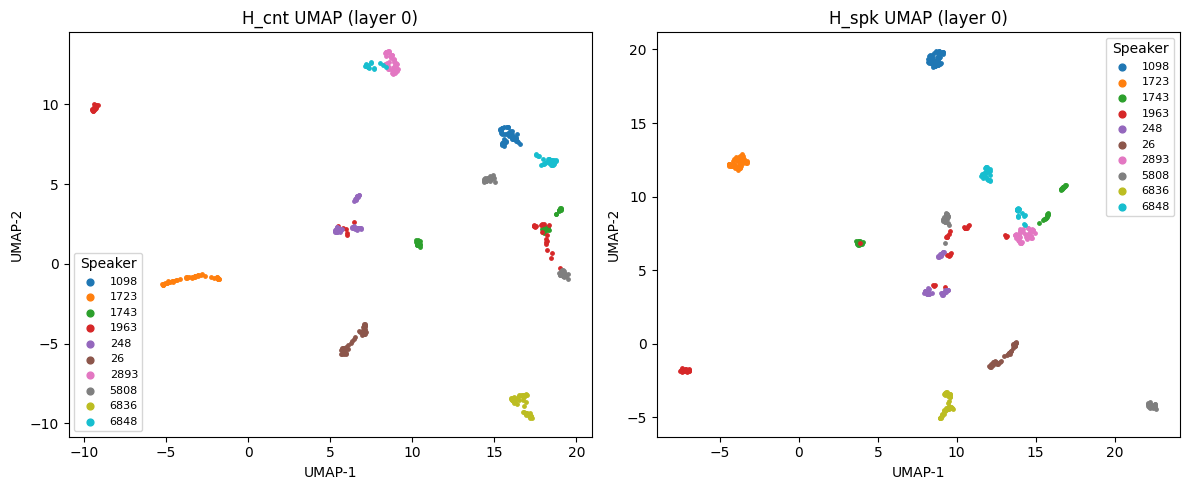

In [13]:
from matplotlib import pyplot as plt
outs = plot_hspk_hcnt_umap(h_list, speaker_ids, mid=512, layer_idx=0, aggregate="mean")

In [14]:
import numpy as np
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler


def classify_speakers_from_hcnt(h_list, speaker_ids, mid, layer_idx=0, aggregate="mean", test_size=0.3, random_state=42):
    """Train a simple classifier on H_cnt (content) features to predict speaker identity.

    A well-disentangled representation should make this hard to predict accurately,
    since H_cnt is expected to be speaker-invariant.

    `h_list` items are dicts from `sample_and_run_inference` (`mid` is then ignored)
    or legacy `h_stacked` tensors [B, L, dict_dim, T].
    """
    labels = [str(spk_id).split("-")[0] for spk_id in speaker_ids]

    feats = []
    for h_stacked in h_list:
        if isinstance(h_stacked, dict):
            # Output of sample_and_run_inference: "cnt" is [1, L, K_cnt, T].
            h_cnt = h_stacked["cnt"].detach().cpu().squeeze(0)[layer_idx].numpy()  # [K_cnt, T]
        else:
            h = h_stacked.detach().cpu()
            if h.ndim == 4:
                h = h.squeeze(0)  # [L, dict_dim, T]
            h_cnt = h[layer_idx, :mid, :].numpy()  # [mid, T]
        feat = h_cnt.mean(axis=1) if aggregate == "mean" else h_cnt.max(axis=1)
        feats.append(feat)

    X = np.stack(feats, axis=0)
    y = np.array(labels)

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=test_size, random_state=random_state, stratify=y
    )

    scaler = StandardScaler()
    X_train = scaler.fit_transform(X_train)
    X_test = scaler.transform(X_test)

    clf = LogisticRegression(max_iter=1000)
    clf.fit(X_train, y_train)

    y_pred = clf.predict(X_test)
    acc = accuracy_score(y_test, y_pred)
    print(f"Speaker classification accuracy from H_cnt: {acc:.4f}")
    print(classification_report(y_test, y_pred))

    return clf, acc


clf, acc = classify_speakers_from_hcnt(h_list, speaker_ids, mid=256, layer_idx=3, aggregate="mean")

Speaker classification accuracy from H_cnt: 0.9733
              precision    recall  f1-score   support

        1098       0.88      1.00      0.94        15
        1723       1.00      1.00      1.00        15
        1743       0.94      1.00      0.97        15
        1963       1.00      0.93      0.97        15
         248       1.00      1.00      1.00        15
          26       1.00      1.00      1.00        15
        2893       1.00      0.87      0.93        15
        5808       1.00      1.00      1.00        15
        6836       0.94      1.00      0.97        15
        6848       1.00      0.93      0.97        15

    accuracy                           0.97       150
   macro avg       0.98      0.97      0.97       150
weighted avg       0.98      0.97      0.97       150



In [15]:
import numpy as np
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score
from sklearn.model_selection import train_test_split
from sklearn.multiclass import OneVsRestClassifier
from sklearn.preprocessing import StandardScaler


def classify_chars_from_hspk(
    h_list,
    transcripts,
    layer_idx=0,
    aggregate="mean",
    min_count=20,
    test_size=0.3,
    random_state=42,
):
    """Predict which characters occur in an utterance from H_spk features.

    Counterpart of `classify_speakers_from_hcnt`: H_spk is expected to be
    content-invariant, so a well-disentangled representation should make this
    hard (low F1, close to the majority/prior baseline).

    `h_list` items are dicts from `sample_and_run_inference`. "spk" [1, L, K_spk, 1]
    is used directly; with aggregate="mean"/"max" over time, "spk_mat" [1, L, K_spk, T]
    is used instead. Pass aggregate=None to use "spk".
    `transcripts` is a list of strings (one per item). Characters appearing in
    fewer than `min_count` utterances are ignored. Use phoneme strings
    (space-separated) with `phonemes=True` semantics by passing token lists instead.
    """
    # Each transcript may be a string (characters) or a list of tokens (e.g. phonemes).
    token_sets = [set(t) if not isinstance(t, str) else set(t.lower()) - {" "} for t in transcripts]

    counts = {}
    for s in token_sets:
        for tok in s:
            counts[tok] = counts.get(tok, 0) + 1
    vocab = sorted(tok for tok, c in counts.items() if c >= min_count)
    if not vocab:
        raise ValueError(f"No token appears in >= {min_count} utterances; lower min_count.")
    tok2idx = {tok: i for i, tok in enumerate(vocab)}

    feats = []
    for h in h_list:
        if aggregate is None:
            f = h["spk"].detach().cpu().squeeze(0)[layer_idx].numpy().reshape(-1)  # [K_spk]
        else:
            m = h["spk_mat"].detach().cpu().squeeze(0)[layer_idx].numpy()  # [K_spk, T]
            f = m.mean(axis=1) if aggregate == "mean" else m.max(axis=1)
        feats.append(f)

    X = np.stack(feats, axis=0)
    Y = np.zeros((len(token_sets), len(vocab)), dtype=int)
    for i, s in enumerate(token_sets):
        for tok in s:
            if tok in tok2idx:
                Y[i, tok2idx[tok]] = 1

    X_train, X_test, Y_train, Y_test = train_test_split(
        X, Y, test_size=test_size, random_state=random_state
    )

    scaler = StandardScaler()
    X_train = scaler.fit_transform(X_train)
    X_test = scaler.transform(X_test)

    # Drop labels that are constant in the train split (can't be fit).
    keep = np.where((Y_train.sum(0) > 0) & (Y_train.sum(0) < len(Y_train)))[0]
    clf = OneVsRestClassifier(LogisticRegression(max_iter=1000))
    clf.fit(X_train, Y_train[:, keep])

    Y_pred = clf.predict(X_test)
    Y_true = Y_test[:, keep]
    macro_f1 = f1_score(Y_true, Y_pred, average="macro", zero_division=0)
    micro_f1 = f1_score(Y_true, Y_pred, average="micro", zero_division=0)
    # Baseline: always predict "present" for every token.
    base_f1 = f1_score(Y_true, np.ones_like(Y_true), average="micro", zero_division=0)

    print(f"Character classification from H_spk: macro-F1={macro_f1:.4f}, micro-F1={micro_f1:.4f} (all-present baseline micro-F1={base_f1:.4f})")
    per_tok = f1_score(Y_true, Y_pred, average=None, zero_division=0)
    for j, f1 in sorted(zip(keep, per_tok), key=lambda x: -x[1])[:10]:
        print(f"  {vocab[j]!r}: F1={f1:.3f} (in {counts[vocab[j]]} utts)")

    return clf, {"macro_f1": macro_f1, "micro_f1": micro_f1, "baseline_micro_f1": base_f1}

In [16]:
clf, res = classify_chars_from_hspk(h_list, transcripts, layer_idx=3, aggregate="mean")

NameError: name 'transcripts' is not defined